# Yield Curve Lab: data backfill

Pulls the **Treasury par yield curve (1990 to today)** and **EFFR / SOFR** into `data/`.

- Treasury data: one CSV per year, from the same "Download CSV" link as the Treasury's Daily Treasury Rates page.
- EFFR, SOFR, and DFF (daily fed funds, covers pre-2000): from FRED.
- Safe to rerun: finished past years are skipped, and the current year is always refreshed.

**Before running:** optionally set `FRED_API_KEY` in the config cell. Without it the notebook uses FRED's public CSV download.

In [2]:
# Run once if needed
# %pip install pandas requests fredapi matplotlib

## 1. Settings

In [3]:
import io
import logging
import os
import re
import time
from datetime import date
from pathlib import Path

import pandas as pd
import requests

START_YEAR = 1990
REFRESH_ALL = False          # True = re-download every year, not just the current one
FRED_API_KEY = os.environ.get("FRED_API_KEY", "")   # or paste your key here as a string

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw" / "treasury"
RAW_DIR.mkdir(parents=True, exist_ok=True)

TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all"
    "?type=daily_treasury_yield_curve&field_tdr_date_value={year}&page&_format=csv"
)
FRED_SERIES = {"EFFR": "effr", "SOFR": "sofr", "DFF": "dff"}
MATURITY_ORDER = ["1m", "1_5m", "2m", "3m", "4m", "6m", "1y", "2y", "3y", "5y", "7y", "10y", "20y", "30y"]

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s",
                    handlers=[logging.FileHandler(DATA_DIR / "backfill.log"), logging.StreamHandler()],
                    force=True)

## 2. Helper functions

In [4]:
def normalize_col(name: str) -> str:
    """'1 Mo' -> '1m', '1.5 Month' -> '1_5m', '10 Yr' -> '10y', 'Date' -> 'date'."""
    s = name.strip().lower()
    m = re.match(r"^(\d+(?:\.\d+)?)\s*(mo|month|months|m)\b", s)
    if m:
        return m.group(1).replace(".", "_") + "m"
    m = re.match(r"^(\d+(?:\.\d+)?)\s*(yr|year|years|y)\b", s)
    if m:
        return m.group(1).replace(".", "_") + "y"
    return re.sub(r"[^a-z0-9]+", "_", s).strip("_")


def fetch_year(year: int, session: requests.Session, retries: int = 4) -> str:
    last = None
    for attempt in range(retries):
        try:
            r = session.get(TREASURY_URL.format(year=year), timeout=60)
            r.raise_for_status()
            head = r.text.lstrip()[:200].lower()
            if not head.startswith("date") and '"date"' not in head:
                raise ValueError("response does not look like the expected CSV")
            return r.text
        except Exception as exc:
            last = exc
            wait = 2 ** attempt
            logging.warning("Year %s attempt %d failed (%s); retrying in %ds", year, attempt + 1, exc, wait)
            time.sleep(wait)
    raise RuntimeError(f"Could not download {year}: {last}")

## 3. Download the Treasury curve, one file per year

In [5]:
end_year = date.today().year
failed = []

with requests.Session() as session:
    session.headers["User-Agent"] = "yield-curve-lab/1.0 (student research project)"
    for year in range(START_YEAR, end_year + 1):
        path = RAW_DIR / f"{year}.csv"
        if path.exists() and not REFRESH_ALL and year < end_year:
            logging.info("%s: already downloaded, skipping", year)
            continue
        try:
            path.write_text(fetch_year(year, session))
            logging.info("%s: downloaded", year)
        except Exception as exc:
            logging.error("%s", exc)
            failed.append(year)
        time.sleep(1.0)   # be polite to the server

print("Failed years:", failed or "none")

2026-11-15 12:03:06,997 INFO 1990: downloaded
2026-11-15 12:03:08,339 INFO 1991: downloaded
2026-11-15 12:03:09,677 INFO 1992: downloaded
2026-11-15 12:03:11,126 INFO 1993: downloaded
2026-11-15 12:03:12,551 INFO 1994: downloaded
2026-11-15 12:03:13,984 INFO 1995: downloaded
2026-11-15 12:03:15,184 INFO 1996: downloaded
2026-11-15 12:03:16,543 INFO 1997: downloaded
2026-11-15 12:03:17,886 INFO 1998: downloaded
2026-11-15 12:03:19,216 INFO 1999: downloaded
2026-11-15 12:03:20,640 INFO 2000: downloaded
2026-11-15 12:03:21,973 INFO 2001: downloaded
2026-11-15 12:03:23,406 INFO 2002: downloaded
2026-11-15 12:03:24,826 INFO 2003: downloaded
2026-11-15 12:03:26,123 INFO 2004: downloaded
2026-11-15 12:03:27,501 INFO 2005: downloaded
2026-11-15 12:03:28,775 INFO 2006: downloaded
2026-11-15 12:03:30,016 INFO 2007: downloaded
2026-11-15 12:03:31,256 INFO 2008: downloaded
2026-11-15 12:03:32,621 INFO 2009: downloaded
2026-11-15 12:03:33,910 INFO 2010: downloaded
2026-11-15 12:03:35,387 INFO 2011:

Failed years: none


## 4. Combine into one table

Each yield is in percent. Blank cells are expected in early years: the 1.5-month point starts in Feb 2025, 4-month in Oct 2022, 2-month in Oct 2018, the 20-year has a gap from 1987 to 1993, and the 30-year is missing from 2002 to 2006.

In [6]:
frames = []
for year in range(START_YEAR, end_year + 1):
    path = RAW_DIR / f"{year}.csv"
    if not path.exists():
        continue
    df = pd.read_csv(path, na_values=["N/A", "NA", ""])
    df.columns = [normalize_col(c) for c in df.columns]
    df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
    for c in df.columns:
        if c != "date":
            df[c] = pd.to_numeric(df[c], errors="coerce")
    frames.append(df)

treasury = pd.concat(frames, ignore_index=True)
treasury = treasury.drop_duplicates(subset="date", keep="last").sort_values("date")
ordered = [c for c in MATURITY_ORDER if c in treasury.columns]
extras = [c for c in treasury.columns if c not in ordered and c != "date"]
treasury = treasury[["date"] + ordered + extras].set_index("date").dropna(axis=1, how="all")

treasury.to_csv(DATA_DIR / "treasury_par_yield_curve.csv")
print(f"{len(treasury):,} rows, {treasury.index.min().date()} to {treasury.index.max().date()}")
treasury.tail()

9,224 rows, 1990-01-02 to 2026-11-13


,1m,1_5m,2m,3m,4m,6m,1y,2y,3y,5y,7y,10y,20y,30y
date,,,,,,,,,,,,,,
2026-11-06,4.02,4.07,4.15,4.19,4.19,4.23,4.33,4.51,4.59,4.64,4.74,4.86,5.29,5.26
2026-11-09,4.04,4.13,4.19,4.24,4.20,4.26,4.38,4.56,4.58,4.67,4.76,4.88,5.29,5.26
2026-11-10,4.05,4.16,4.21,4.30,4.28,4.38,4.56,4.73,4.74,4.81,4.89,4.98,5.39,5.35
2026-11-12,4.12,4.18,4.26,4.32,4.35,4.42,4.65,4.86,4.90,4.95,5.02,5.10,5.48,5.43
2026-11-13,4.10,4.18,4.26,4.32,4.34,4.42,4.65,4.88,4.92,4.98,5.05,5.15,5.52,5.47


In [7]:
# Sanity check: a full year should have about 250 trading days
counts = treasury.groupby(treasury.index.year).size()
short = counts[(counts < 200) & (counts.index < end_year)]
print("Years with fewer than 200 rows (check these):", short.to_dict() or "none")
counts.tail(8)

Years with fewer than 200 rows (check these): none


date
2019    250
2020    251
2021    251
2022    249
2023    250
2024    250
2025    249
2026    218
dtype: int64

Fit date: 2026-11-13


beta0      5.718887
beta1     -1.648480
beta2     99.890347
beta3   -100.000000
tau1       1.661560
tau2       1.689282
Name: 2026-11-13 00:00:00, dtype: float64

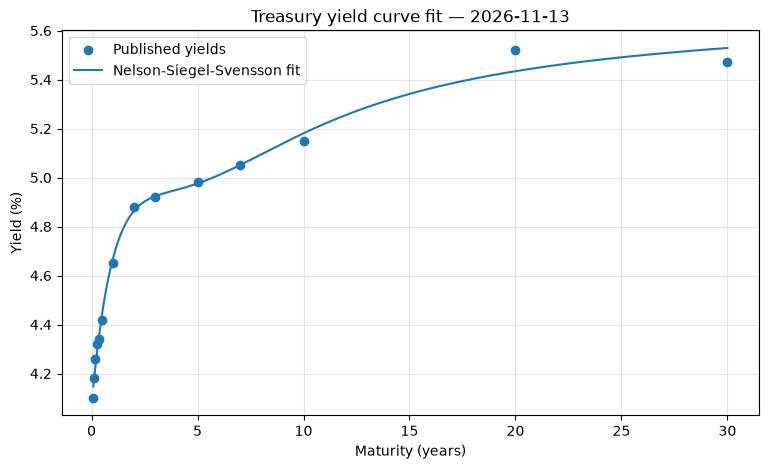

In [14]:
import numpy as np
from scipy.optimize import least_squares
import matplotlib.pyplot as plt

# Maturities in years, matching the Treasury column names.
maturity_years = {
    "1m": 1 / 12, "1_5m": 1.5 / 12, "2m": 2 / 12,
    "3m": 0.25, "4m": 1 / 3, "6m": 0.5,
    "1y": 1, "2y": 2, "3y": 3, "5y": 5,
    "7y": 7, "10y": 10, "20y": 20, "30y": 30,
}

def nss_yield(maturity, beta0, beta1, beta2, beta3, tau1, tau2):
    x1, x2 = maturity / tau1, maturity / tau2
    loading1 = -np.expm1(-x1) / x1
    loading2 = -np.expm1(-x2) / x2
    return (
        beta0
        + beta1 * loading1
        + beta2 * (loading1 - np.exp(-x1))
        + beta3 * (loading2 - np.exp(-x2))
    )

latest = treasury.iloc[-1].dropna()
latest = latest[[c for c in MATURITY_ORDER if c in latest.index]]
observed_maturities = np.array([maturity_years[c] for c in latest.index])
observed_yields = latest.to_numpy(dtype=float)

if len(observed_yields) < 6:
    raise ValueError("At least six published maturities are needed to fit six NSS parameters.")

long_yield, short_yield = observed_yields[-1], observed_yields[0]
initial_beta = [long_yield, short_yield - long_yield, 0, 0]

bounds = (
    [-100, -100, -100, -100, 0.05, 0.05],
    [100, 100, 100, 100, 30, 30],
)

# Try several starting values to reduce sensitivity to the initial guess.
fits = []
for tau1_start, tau2_start in [(1.5, 5), (0.5, 3), (2, 10)]:
    result = least_squares(
        lambda p: nss_yield(observed_maturities, *p) - observed_yields,
        initial_beta + [tau1_start, tau2_start],
        bounds=bounds,
        x_scale="jac",
        max_nfev=1000,
    )
    fits.append(result)

best_fit = min(fits, key=lambda result: np.sum(result.fun**2))
nss_params = pd.Series(
    best_fit.x,
    index=["beta0", "beta1", "beta2", "beta3", "tau1", "tau2"],
    name=latest.name,
)

print(f"Fit date: {latest.name:%Y-%m-%d}")
display(nss_params)

smooth_maturities = np.linspace(observed_maturities.min(), observed_maturities.max(), 300)
plt.figure(figsize=(9, 5))
plt.scatter(observed_maturities, observed_yields, label="Published yields", zorder=3)
plt.plot(
    smooth_maturities,
    nss_yield(smooth_maturities, *best_fit.x),
    label="Nelson-Siegel-Svensson fit",
)
plt.xlabel("Maturity (years)")
plt.ylabel("Yield (%)")
plt.title(f"Treasury yield curve fit — {latest.name:%Y-%m-%d}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

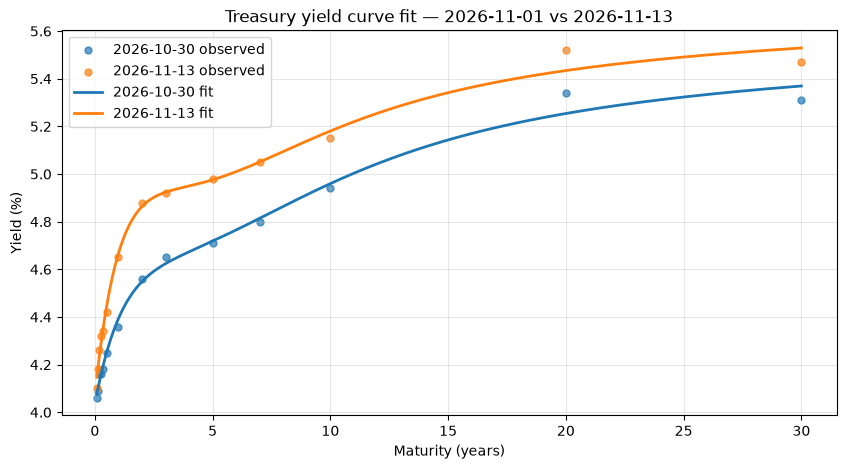

In [15]:
date_1 = treasury.index[treasury.index <= "2026-11-01"][-1]
date_2 = pd.Timestamp("2026-11-13")

def fit_curve_for_date(date_value):
    row = treasury.loc[date_value].dropna()
    row = row[[c for c in MATURITY_ORDER if c in row.index]]
    if len(row) < 6:
        raise ValueError(f"Not enough maturities on {date_value}")
    
    observed_maturities = np.array([maturity_years[c] for c in row.index], dtype=float)
    observed_yields = row.to_numpy(dtype=float)
    
    long_yield, short_yield = observed_yields[-1], observed_yields[0]
    initial_beta = [long_yield, short_yield - long_yield, 0, 0]
    
    fits = []
    for tau1_start, tau2_start in [(1.5, 5), (0.5, 3), (2, 10)]:
        result = least_squares(
            lambda p: nss_yield(observed_maturities, *p) - observed_yields,
            initial_beta + [tau1_start, tau2_start],
            bounds=bounds,
            x_scale="jac",
            max_nfev=1000,
        )
        fits.append(result)
    
    best_fit_date = min(fits, key=lambda result: np.sum(result.fun**2))
    return observed_maturities, observed_yields, best_fit_date

mats_1, yields_1, fit_1 = fit_curve_for_date(date_1)
mats_2, yields_2, fit_2 = fit_curve_for_date(date_2)

smooth_maturities = np.linspace(
    min(mats_1.min(), mats_2.min()),
    max(mats_1.max(), mats_2.max()),
    400,
)

plt.figure(figsize=(10, 5))
plt.scatter(mats_1, yields_1, color="tab:blue", s=25, alpha=0.7, label=f"{date_1.date()} observed")
plt.scatter(mats_2, yields_2, color="tab:orange", s=25, alpha=0.7, label=f"{date_2.date()} observed")

plt.plot(
    smooth_maturities,
    nss_yield(smooth_maturities, *fit_1.x),
    color="tab:blue",
    linewidth=2,
    label=f"{date_1.date()} fit",
)
plt.plot(
    smooth_maturities,
    nss_yield(smooth_maturities, *fit_2.x),
    color="tab:orange",
    linewidth=2,
    label=f"{date_2.date()} fit",
)

plt.xlabel("Maturity (years)")
plt.ylabel("Yield (%)")
plt.title("Treasury yield curve fit — 2026-11-01 vs 2026-11-13")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [30]:
import numpy as np
from scipy.optimize import least_squares

def basis(tau, l1, l2):
    t1, t2 = tau / l1, tau / l2
    f1 = (1 - np.exp(-t1)) / t1
    f2 = f1 - np.exp(-t1)
    f3 = (1 - np.exp(-t2)) / t2 - np.exp(-t2)
    return np.column_stack([np.ones_like(tau), f1, f2, f3])

def nss_spot(tau, b0, b1, b2, b3, l1, l2):
    tau = np.atleast_1d(np.asarray(tau, float))
    return basis(tau, l1, l2) @ np.array([b0, b1, b2, b3])

def par_from_spot(spot_params, T):
    """Par yield (%) for maturity T years from a fitted spot curve."""
    d = lambda t: np.exp(-nss_spot(t, *spot_params) / 100 * t)
    if T <= 0.5:
        return ((1 / d(T) - 1) / T * 100)[0]
    t = np.arange(0.5, T + 1e-9, 0.5)
    return (2 * (1 - d(T)) / d(t).sum() * 100)[0]

def fit_nss(tau, y_par, w=None):
    tau, y_par = np.asarray(tau, float), np.asarray(y_par, float)
    w = np.ones_like(y_par) if w is None else np.asarray(w, float)

    # Stage 1: grid over lambdas, linear least squares for the betas
    best = None
    for l1 in np.linspace(0.3, 6, 25):
        for l2 in np.linspace(2, 30, 29):
            if l2 < 1.2 * l1:
                continue
            X = basis(tau, l1, l2)
            b, *_ = np.linalg.lstsq(X * w[:, None], y_par * w, rcond=None)
            sse = np.sum((w * (X @ b - y_par)) ** 2)
            if best is None or sse < best[0]:
                best = (sse, np.r_[b, l1, l2])

    # Stage 2: polish all six parameters against PAR yields
    def resid(p):
        return w * np.array([par_from_spot(p, T) for T in tau]) - w * y_par

    lo = [-np.inf] * 4 + [0.1, 0.5]
    hi = [np.inf] * 4 + [10, 40]
    res = least_squares(resid, best[1], bounds=(lo, hi))
    return res.x

def report(tau, y_par, params):
    fit = np.array([par_from_spot(params, T) for T in tau])
    err_bp = (fit - np.asarray(y_par)) * 100
    for T, e in zip(tau, err_bp):
        print(f"{T:6.2f}y  {e:+6.1f} bp {'  <-- over 1 bp' if abs(e) > 1 else ''}")
    print("max abs error:", round(np.abs(err_bp).max(), 1), "bp")

In [32]:
import itertools
import numpy as np
from scipy.optimize import least_squares, minimize

def basis(tau, l1, l2):
    t1, t2 = tau / l1, tau / l2
    f1 = (1 - np.exp(-t1)) / t1
    f2 = f1 - np.exp(-t1)
    f3 = (1 - np.exp(-t2)) / t2 - np.exp(-t2)
    return np.column_stack([np.ones_like(tau), f1, f2, f3])

def nss_spot(tau, b0, b1, b2, b3, l1, l2):
    tau = np.atleast_1d(np.asarray(tau, float))
    return basis(tau, l1, l2) @ np.array([b0, b1, b2, b3])

def par_from_spot(spot_params, T):
    """Par yield (%) for maturity T years from a fitted spot curve."""
    d = lambda t: np.exp(-nss_spot(t, *spot_params) / 100 * t)
    if T <= 0.5:                                   # simple yield up to 6 months
        return ((1 / d(T) - 1) / T * 100)[0]
    t = np.arange(0.5, T + 1e-9, 0.5)              # semiannual-coupon par formula from 6 months out
    return (2 * (1 - d(T)) / d(t).sum() * 100)[0]

def fit_nss(tau, y_par, w=None, n_starts=12, minimax=True):
    """Fit NSS to par yields. Returns [b0, b1, b2, b3, l1, l2].
    Stage 1: grid over lambdas, least squares for the betas.
    Stage 2: multi-start polish of all six parameters against PAR yields.
    Stage 3: minimax step, minimizes the worst (weighted) error directly."""
    tau, y_par = np.asarray(tau, float), np.asarray(y_par, float)
    w = np.ones_like(y_par) if w is None else np.asarray(w, float)

    # Stage 1: grid over lambdas, keep the best candidates
    cands = []
    for l1 in np.linspace(0.3, 6, 12):
        for l2 in np.linspace(2, 30, 15):
            if l2 < 1.2 * l1:
                continue
            X = basis(tau, l1, l2)
            b, *_ = np.linalg.lstsq(X * w[:, None], y_par * w, rcond=None)
            sse = np.sum((w * (X @ b - y_par)) ** 2)
            cands.append((sse, np.r_[b, l1, l2]))
    cands.sort(key=lambda c: c[0])

    par_all = lambda p: np.array([par_from_spot(p, T) for T in tau])
    resid = lambda p: w * (par_all(p) - y_par)
    lo = [-np.inf] * 4 + [0.1, 0.5]
    hi = [np.inf] * 4 + [10, 40]

    # Stage 2: multi-start least squares in par space
    best = None
    for _, p0 in cands[:n_starts]:
        r = least_squares(resid, p0, bounds=(lo, hi), xtol=1e-12, ftol=1e-12, gtol=1e-12)
        m = np.abs(r.fun).max()
        if best is None or m < best[0]:
            best = (m, r.x)
    p = best[1]

    # Stage 3: minimize the maximum error
    if minimax:
        cons = [{"type": "ineq", "fun": lambda z: z[-1] - resid(z[:-1])},
                {"type": "ineq", "fun": lambda z: z[-1] + resid(z[:-1])}]
        bnds = [(None if np.isinf(a) else a, None if np.isinf(b) else b) for a, b in zip(lo, hi)] + [(0, None)]
        z0 = np.r_[p, np.abs(resid(p)).max()]
        r = minimize(lambda z: z[-1], z0, constraints=cons, bounds=bnds, method="SLSQP",
                     options={"maxiter": 500, "ftol": 1e-12})
        if np.abs(resid(r.x[:-1])).max() < best[0]:
            p = r.x[:-1]
    return p

def report(tau, y_par, params):
    fit = np.array([par_from_spot(params, T) for T in tau])
    err_bp = (fit - np.asarray(y_par)) * 100
    for T, e in zip(tau, err_bp):
        print(f"{T:6.2f}y  {e:+6.2f} bp" + ("  <-- over 1 bp" if abs(e) > 1 else ""))
    print("max abs error:", round(np.abs(err_bp).max(), 2), "bp | betas:", np.round(params[:4], 1),
          "| lambdas:", np.round(params[4:], 1))

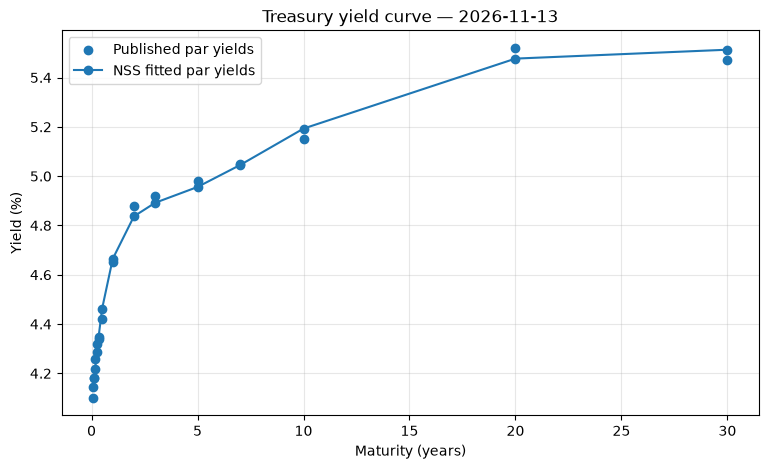

[3.19426084 0.86899729 2.44651456 7.47437605]
Lambda 1: 1.176825
Lambda 2: 15.473174
Fitted minus published yields on 2026-11-13:
1m     +4.30
1_5m   +0.07
2m     -4.30
3m     -3.45
4m     +0.91
6m     +4.30
1y     +1.46
2y     -4.30
3y     -2.80
5y     -2.39
7y     -0.52
10y    +4.30
20y    -4.30
30y    +4.30


In [34]:
curve_date = treasury.index.max()
curve_row = treasury.loc[curve_date].dropna()
curve_row = curve_row[[m for m in MATURITY_ORDER if m in curve_row.index]]

curve_maturities = np.array([maturity_years[m] for m in curve_row.index], dtype=float)
curve_yields = curve_row.to_numpy(dtype=float)
curve_params = fit_nss(curve_maturities, curve_yields)

fitted_yields = np.array([par_from_spot(curve_params, T) for T in curve_maturities])

plt.figure(figsize=(9, 5))
plt.scatter(curve_maturities, curve_yields, label="Published par yields", zorder=3)
plt.plot(curve_maturities, fitted_yields, marker="o", label="NSS fitted par yields")
plt.xlabel("Maturity (years)")
plt.ylabel("Yield (%)")
plt.title(f"Treasury yield curve — {curve_date:%Y-%m-%d}")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
print(curve_params[:4])
differences_bp = pd.Series(
    (fitted_yields - curve_yields) * 100,
    index=curve_row.index,
    name="Difference (bp)",
)

print(f"Lambda 1: {curve_params[4]:.6f}")
print(f"Lambda 2: {curve_params[5]:.6f}")
print(f"Fitted minus published yields on {curve_date:%Y-%m-%d}:")
print(differences_bp.to_string(float_format=lambda value: f"{value:+.2f}"))

Why the short end is hard. Going from 1M to 6M, the yield steps up by uneven amounts: +8, +8, +6, +2, +8 bp. Then it jumps +23 bp to 1Y and +23 bp to 2Y, and flattens abruptly: only +4 bp from 2Y to 3Y and +6 bp over the next two years. A curve with six smooth parameters can’t follow lumps of 2 to 8 bp at the front and a sharp knee at 2Y. Your λ1 of 1.18 puts the first hump near 2.1 years (about 1.8 × λ1), so the optimizer is trying to catch that knee. On 11-09 the 4M yield (4.20) is even below the 3M (4.24), which no smoothly rising curve can match.

Minimax hurts on all 14 maturities. It lowers the worst error from 5.3 to 4.3 bp but raises the RMS from 2.4 to 3.4 bp, because the bills dominate the worst case. For the full-curve fit, I’d use minimax=False.
A third hump doesn’t help. The 8-parameter version got a max of 4.33 bp with betas in the hundreds, so extra flexibility isn’t the answer here.


Split the fit. Use the published 1M to 6M yields as they are, since they’re real quotes, and fit NSS to 1Y and longer. Expect 1.4 to 2.9 bp max on this data, and report that honestly.
Add a residual correction if the brief’s 1 bp is strict. Interpolate each day’s fit residuals (for example with a cubic spline) and add them back, so the curve passes through every published point. The cost is some extra wiggle between points.
Use a monotone convex spline, as the Treasury does. It matches every point, but you lose the six-number summary.
Restate the goal as something the model can meet, such as “max under 5 bp across all maturities, with RMS and a list of points above 1 bp,” or the split fit’s numbers.

## 5. EFFR and SOFR from FRED

`DFF` is the daily effective fed funds rate. It is included because `EFFR` only starts in 2000 and `SOFR` in 2018, so `DFF` is the series that covers the 1990s.

In [8]:
if FRED_API_KEY:
    from fredapi import Fred
    fred = Fred(api_key=FRED_API_KEY)
    rates = pd.DataFrame({name: fred.get_series(sid, observation_start=f"{START_YEAR}-01-01")
                          for sid, name in FRED_SERIES.items()})
else:
    logging.warning("No FRED_API_KEY set; using FRED's public CSV download instead")
    r = requests.get("https://fred.stlouisfed.org/graph/fredgraph.csv",
                     params={"id": ",".join(FRED_SERIES), "cosd": f"{START_YEAR}-01-01"}, timeout=60)
    r.raise_for_status()
    rates = pd.read_csv(io.StringIO(r.text), na_values=["."])
    rates = rates.rename(columns={rates.columns[0]: "date"})
    rates["date"] = pd.to_datetime(rates["date"])
    rates = rates.set_index("date").rename(columns=FRED_SERIES)

rates.index.name = "date"
rates = rates.apply(pd.to_numeric, errors="coerce").sort_index()
rates.to_csv(DATA_DIR / "policy_rates.csv")
print(f"{len(rates):,} rows, latest EFFR {rates['effr'].dropna().iloc[-1]}, latest SOFR {rates['sofr'].dropna().iloc[-1]}")
rates.tail()

2026-11-15 12:08:28,250 WARNING No FRED_API_KEY set; using FRED's public CSV download instead


ParserError: Error tokenizing data. C error: Expected 1 fields in line 3, saw 3


## 6. Quick look

In [ ]:
import matplotlib.pyplot as plt

both = treasury[["3m", "2y", "10y"]].join(rates[["dff"]], how="left")
ax = both.plot(figsize=(11, 4), linewidth=1)
ax.set_ylabel("percent")
ax.set_title("3M, 2Y, 10Y Treasury par yields and daily fed funds rate")
plt.show()